# Exercice 6 — Régression linéaire

In [102]:
import numpy as np

import pandas as pd

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LinearRegression

from sklearn.metrics import r2_score , mean_absolute_error 

from math import sqrt

import matplotlib.pyplot as plt

### Génère un dataset de 300 biens immobiliers

In [103]:
n = 300

surface_m2 =  np.random.uniform(20, 250, n).astype(int)

nb_pieces = np.random.uniform(1, 8, n).astype(int)

age_bien_annees = np.random.uniform(0,100, n).astype(int)

distance_centre_km = np.random.uniform(0.1, 30, n).round(1)

quartier  =  np.random.choice(["Centre", "Peripherie", "Banlieue"], n)

In [104]:
df  = pd.DataFrame({

    "surface_m2" : surface_m2,

    "nb_pieces" : nb_pieces,

    "age_bien_annees" : age_bien_annees,

    "distance_centre_km" : distance_centre_km,

    "quartier" : quartier
})

Fonction  de calcul de prix

In [105]:
def calcul_prix(df):

    return 50000 + 3000 * df["surface_m2"] + 15000 * df["nb_pieces"] - 500 * df["age_bien_annees"] - 2000 * df["distance_centre_km"] + np.random.normal(loc=0 , scale= 20000)

In [106]:
df["prix_euros"] =  df.apply(calcul_prix,axis=1).round(2)

In [107]:
df

,surface_m2,nb_pieces,age_bien_annees,distance_centre_km,quartier,prix_euros
0,115,3,87,0.3,Peripherie,411093.42
1,192,4,9,18.2,Peripherie,615283.19
2,178,7,62,13.2,Banlieue,666112.56
3,46,3,30,11.5,Peripherie,165351.36
4,109,1,28,9.6,Banlieue,361944.66
...,...,...,...,...,...,...
295,120,3,56,12.2,Banlieue,393647.23
296,153,4,34,6.9,Banlieue,550139.49
297,46,1,70,27.6,Banlieue,53981.69
298,160,4,89,25.4,Centre,494824.64


### Encodage de quartier en one-hot

In [108]:
encoder = OneHotEncoder(handle_unknown="ignore")

result = encoder.fit_transform(df[["quartier"]])

encoded_df = pd.DataFrame(

    result.toarray(),

    columns=encoder.get_feature_names_out(),

    index=df.index
)

df = df.drop(columns=["quartier"])

df = pd.concat([df, encoded_df], axis=1)

df


,surface_m2,nb_pieces,age_bien_annees,distance_centre_km,prix_euros,quartier_Banlieue,quartier_Centre,quartier_Peripherie
0,115,3,87,0.3,411093.42,0.0,0.0,1.0
1,192,4,9,18.2,615283.19,0.0,0.0,1.0
2,178,7,62,13.2,666112.56,1.0,0.0,0.0
3,46,3,30,11.5,165351.36,0.0,0.0,1.0
4,109,1,28,9.6,361944.66,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...
295,120,3,56,12.2,393647.23,1.0,0.0,0.0
296,153,4,34,6.9,550139.49,1.0,0.0,0.0
297,46,1,70,27.6,53981.69,1.0,0.0,0.0
298,160,4,89,25.4,494824.64,0.0,1.0,0.0


### Séparation train (80%) / test (20%)

In [109]:
x = df.drop("prix_euros" , axis=1)

y = df["prix_euros"]


In [110]:
x_train , x_test , y_train , y_test = train_test_split(x, y, test_size=0.2)

### Entraînement d'un LinearRegression

In [111]:
model =  LinearRegression()

model.fit(x_train , y_train)

model.score(x_train,y_train)

model.score(x_test,y_test)

pred = model.predict(x_test)


### Affichage les coefficients associés à chaque variable

Le coefficient de la surface est positif, ce qui signifie que plus un bien immobilier possède une grande surface, plus son prix augmente. Le coefficient de l'âge est négatif, car les biens anciens perdent de la valeur. Le coefficient de la distance au centre est également négatif, car plus un bien est éloigné du centre, plus son prix diminue. Les coefficients obtenus sont proches des valeurs utilisées lors de la génération du dataset, ce qui montre que la régression linéaire a réussi à retrouver les relations présentes dans les données.

### Évaluation avec le R², le MAE et le RMSE sur le test

r2

In [112]:
r2_score(y_test,pred)

0.992267103417804

mae

In [113]:
mean_absolute_error(y_test,pred)

14141.72762691444

rmae

In [114]:
sqrt(mean_absolute_error(y_test,pred))

118.91899607259742

### Nuage de points valeurs réelles vs valeurs prédites

Text(0, 0.5, 'Prix predit ')

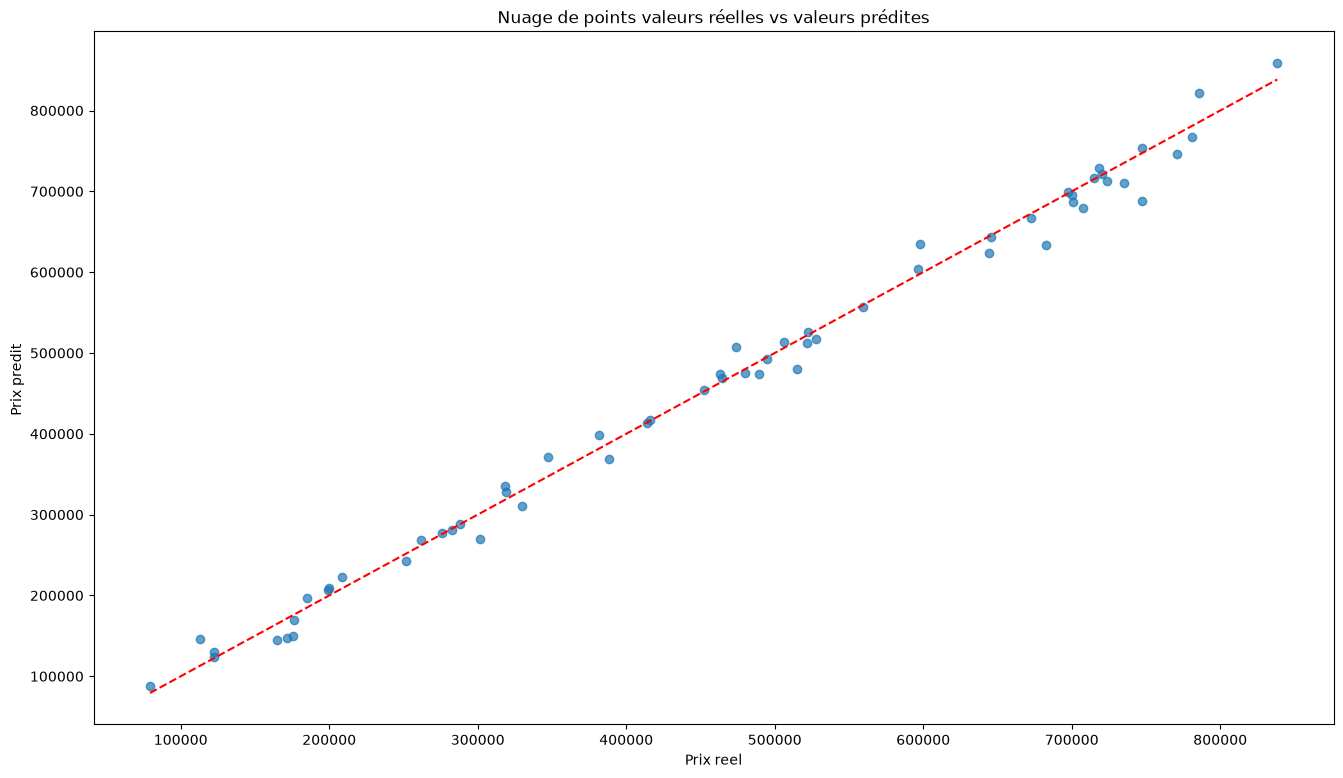

In [124]:
fig , ax = plt.subplots(figsize=(16,9))

ax.set_title("Nuage de points valeurs réelles vs valeurs prédites")

ax.scatter(y_test,pred,alpha=0.7)

ax.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

ax.set_xlabel("Prix reel")

ax.set_ylabel("Prix predit ")
